In [1]:
from model.models import MOFConditionPredictor

import warnings

warnings.filterwarnings(
    "ignore",
    message="The usage of `scatter\\(reduce='max'\\).*",
    category=UserWarning,
)

%load_ext autoreload
%autoreload 2


IDX_TO_METALSALT ={
    0: 'Cu(NO3)2.2.5H2O',
    1: 'FeCl2.4H2O',
    2: 'CdCl2',
    3: 'PbI2',
    4: 'Cu(OAc)2.H2O',
    5: 'Co(ClO4)2.6H2O',
    6: 'Zn(OAc)2.H2O',
    7: 'Mn(ClO4)2.6H2O',
    8: 'CuBr2',
    9: 'FeCl3.6H2O',
    10: 'Cu(NO3)2.6H2O',
    11: 'Cu(OH)2',
    12: 'ZnSO4.7H2O',
    13: 'Cd(OAc)2.2H2O',
    14: 'CoCl2',
    15: 'Tb(NO3)3.5H2O',
    16: 'Cu(NO3)2.4H2O',
    17: 'CaCl2',
    18: 'CrCl3.6H2O',
    19: 'Cu(NO3)2.2H2O',
    20: 'ZnO',
    21: 'ErCl3.6H2O',
    22: 'ZnCO3',
    23: 'Zn(OAc)2.2H2O',
    24: 'Cd(NO3)2',
    25: 'Mn(OAc)2',
    26: 'Ba(NO3)2',
    27: 'AgCF3SO3',
    28: 'AgC2F5CO2',
    29: 'AgBF4',
    30: 'SrCl2.6H2O',
    31: 'CuCl2',
    32: 'Pb(OAc)2',
    33: 'Cu(OAc)2',
    34: 'ZnCl2.6H2O',
    35: 'Cu(ClO4)2',
    36: 'Sm(NO3)3.6H2O',
    37: 'Cu(ClO4)2.6H2O',
    38: 'NH4VO3',
    39: 'CuSO4.5H2O',
    40: 'ZrOCl2.8H2O',
    41: 'Cd(NO3).4H2O',
    42: 'VO2',
    43: 'Pb(NO3)2',
    44: 'HgCl2',
    45: 'V2O5',
    46: 'MnCl2',
    47: 'LiOH.H2O',
    48: 'La(NO3)3.6H2O',
    49: 'EuCl3.6H2O',
    50: 'Cu(NO3)2.3H2O',
    51: 'ZnSO4.6H2O',
    52: 'Eu(NO3)3.6H2O',
    53: 'Ni(OAc)2.4H2O',
    54: 'Zn(NO3)2.4H2O',
    55: 'Ag2O',
    56: 'In(NO3)3.4.5H2O',
    57: 'Co(malo).2H2O',
    58: 'K2CO3',
    59: 'CoSO4.7H2O',
    60: 'Mn(NO3)2.6H2O',
    61: 'Cu(NO3)2',
    62: 'CuBr',
    63: 'MoO3',
    64: 'Cu2O',
    65: 'Gd(NO3)3.6H2O',
    66: 'CdBr2.4H2O',
    67: 'CuCl2.2H2O',
    68: 'Cd(BF4)2.6H2O',
    69: 'Ag2CO3',
    70: 'La2O3',
    71: 'CdCl2.2H2O',
    72: 'Nd2O3',
    73: 'AgI',
    74: 'NiCl2.6H2O',
    75: 'Ce(NO3)3.6H2O',
    76: 'NaC2N3',
    77: 'Y(NO3)3.6H2O',
    78: 'MnCl2.4H2O',
    79: 'MnCl2.2H2O',
    80: 'Cd(NCS)2',
    81: 'CuI',
    82: 'Cd(NO3)2.4H2O',
    83: 'Mo2O6',
    84: 'Cu(OAc)2.2H2O',
    85: 'UO2(NO3)2.6H2O',
    86: 'Pr(NO3)3.6H2O',
    87: 'CdCl2.6H2O',
    88: 'Co(OAc)2.4H2O',
    89: 'Mg(NO3)2.6H2O',
    90: 'Cu(O2CCH3)2',
    91: 'CoCl2.6H2O',
    92: 'HgBr2',
    93: 'Na2CO3',
    94: 'Pb(OAc)2.3H2O',
    95: 'SmCl3.6H2O',
    96: 'Zn(NO3)2',
    97: 'ZnI2',
    98: 'Mn(NO3)2.4H2O',
    99: 'Co(NO3)2.6H2O',
    100: 'Co(NCS)2',
    101: 'TbCl3.6H2O',
    102: 'CuCl',
    103: 'NiSO4.6H2O',
    104: 'Zn(NO3)2.6H2O',
    105: 'Hg2(ClO4)2.4H2O',
    106: 'AgClO4',
    107: 'CdCl2.2.5H2O',
    108: 'ZnCl2',
    109: 'CdCl2.H2O',
    110: 'MnCO3',
    111: 'Cu(ClO4)2.H2O',
    112: 'Ni(ClO4)2.6H2O',
    113: 'Cd(NO3)2.6H2O',
    114: 'CoCl2.2H2O',
    115: 'Ni(NO3)2.6H2O',
    116: 'Nd(NO3)3.6H2O',
    117: 'CdI2',
    118: 'Cu(OAc)2.xH2O',
    119: 'Zn(OAc)2',
    120: 'Dy(NO3)3.6H2O',
    121: 'Eu2O3',
    122: 'InCl3',
    123: 'CuCl2.6H2O',
    124: 'Cu(hfac)2',
    125: 'HgI2',
    126: 'Zn(ClO4)2.6H2O',
    127: 'MnSO4.H2O',
    128: 'AgCF3CO2',
    129: 'Tb(NO3)3.6H2O',
    130: 'FeCl3',
    131: 'Cd(ClO4)2.6H2O',
    132: 'NaN3',
    133: 'Mn(OAc)2.4H2O'}

/home/antonio/miniconda3/envs/dinga/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from pathlib import Path

from mofstructure import mofdeconstructor
import numpy as np

from fairmofsyncondition.crystal.crystal2data import DataStructure
from fairmofsyncondition.read_write import coords_library

import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader


target_field, target_dim = "metal_salt", 134

device= "cpu"
top_x = 3  



cif_path = Path("../../../../Zn2C43N6H29O8.cif")
#cif_path = Path("../../../../EDUSIF.cif")
cif_path = Path("ADIQAG_fair.cif")
#cif_path = Path("REWRAN_fair.cif")
#cif_path = Path("REWQUG_fair.cif")


data = DataStructure(str(cif_path)).complete_torch_data()
ase = coords_library.pytorch_geometric_to_ase(data)

mask = [bool(mofdeconstructor.is_metal(i)[0]) for i in ase.get_chemical_symbols()]
metal = np.unique(np.array(ase.get_chemical_symbols())[mask], return_counts=True)[0].item()


In [51]:



make_right_metal = []
for k,v in IDX_TO_METALSALT.items():
    if v[:2] == metal:
        make_right_metal.append(True)
    else:
        make_right_metal.append(False)


model = MOFConditionPredictor(
    target_dim=target_dim,
    global_fields=["lattice", "atomic_one_hot", "oms"]
)
model.load_state_dict(torch.load("best_model_metal_salt/best_model_metal_salt_seed_123.pt", map_location=device))


for batch in DataLoader([data], batch_size=1):
    break

model.eval()

with torch.no_grad():
    logits = model(batch)  # shape: [batch_size, num_classes]

    # Se stai facendo inferenza su una sola MOF
    logits = logits[0]  # shape: [num_classes]

    # make_right_metal deve essere booleano con shape [num_classes]
    make_right_metal = torch.as_tensor(
        make_right_metal,
        dtype=torch.bool,
        device=logits.device
    )

    # get indices of valid classes (where make_right_metal is True)
    valid_class_indices = torch.where(make_right_metal)[0]

    # filter
    valid_logits = logits[valid_class_indices]

    # softmax only valid salts
    valid_probs = F.softmax(logits, dim=-1)[valid_class_indices]

    # top-k only on compatible salts
    top_probs, top_pos = torch.topk(
        valid_probs,
        k=min(top_x, valid_probs.numel()),
        dim=-1
    )

    # convert to original indices
    top_indices = valid_class_indices[top_pos]


for rank, (idx, prob) in enumerate(zip(top_indices, top_probs), start=1):
    idx = int(idx.item())
    prob = float(prob.item())

    name = IDX_TO_METALSALT[idx]

    print(f"{rank}. idx={idx} | prob={prob:.4f} | {name}")


1. idx=48 | prob=0.2800 | La(NO3)3.6H2O
2. idx=70 | prob=0.0161 | La2O3


# compute top at k using the filter on the right metal satl

In [35]:
import re
import torch
import torch.nn.functional as F
import numpy as np

from torch_geometric.loader import DataLoader
from fairmofsyncondition.read_write import coords_library
from mofstructure import mofdeconstructor


# ============================================================
# 1. Utility: estrai metallo dalla MOF
# ============================================================

def get_mof_metal(data):
    ase = coords_library.pytorch_geometric_to_ase(data)

    symbols = np.array(ase.get_chemical_symbols())
    is_metal_mask = np.array([
        bool(mofdeconstructor.is_metal(sym)[0])
        for sym in symbols
    ])

    metals, counts = np.unique(symbols[is_metal_mask], return_counts=True)
    if len(metals) == 0:
        raise ValueError("Nessun metallo trovato nella MOF.")

    if len(metals) > 1:
        # prendi il metallo più frequente
        metal = metals[np.argmax(counts)]
    else:
        metal = metals[0]

    return metals[0]


# ============================================================
# 2. Utility: estrai metallo dal nome del salt
# ============================================================

def get_salt_metal(salt_name):
    """
    Esempi:
    Zn(OAc)2.H2O -> Zn
    CuCl2 -> Cu
    Co(NO3)2 -> Co
    """
    match = re.match(r"^[A-Z][a-z]?", salt_name)
    if match is None:
        raise ValueError(f"Impossibile estrarre il metallo da: {salt_name}")
    return match.group(0)


# ============================================================
# 3. Crea mask classi compatibili
# ============================================================

def build_metal_mask(metal, idx_to_metalsalt, device=None):
    num_classes = len(idx_to_metalsalt)

    mask = torch.zeros(num_classes, dtype=torch.bool)
    for idx in range(num_classes):
        salt_name = idx_to_metalsalt[idx]
        salt_metal = get_salt_metal(salt_name)

        if salt_metal == metal:
            mask[idx] = True

    if mask.sum() == 0:
        raise ValueError(f"Nessun salt compatibile trovato per metal={metal}")

    if device is not None:
        mask = mask.to(device)

    return mask


# ============================================================
# 4. Predizione top-k masked
# ============================================================

def predict_topk_masked(model, data, idx_to_metalsalt, top_k=3, device="cpu"):
    model.eval()

    data = data.to(device)
    metal = get_mof_metal(data)

    loader = DataLoader([data], batch_size=1)
    batch = next(iter(loader)).to(device)

    with torch.no_grad():
        logits = model(batch)          # [1, num_classes]
        logits = logits.squeeze(0)     # [num_classes]

        metal_mask = build_metal_mask(
            metal=metal,
            idx_to_metalsalt=idx_to_metalsalt,
            device=logits.device
        )

        valid_indices = torch.where(metal_mask)[0]
        valid_logits = logits[valid_indices]

        valid_probs = F.softmax(valid_logits, dim=-1)

        top_probs, top_pos = torch.topk(
            valid_probs,
            k=min(top_k, valid_probs.numel())
        )

        top_indices = valid_indices[top_pos]

    results = []

    for idx, prob in zip(top_indices, top_probs):
        idx = int(idx.item())
        prob = float(prob.item())

        results.append({
            "idx": idx,
            "prob": prob,
            "name": idx_to_metalsalt[idx],
            "metal": metal,
        })

    return results


# ============================================================
# 5. Caricamento modello
# ============================================================

device = "cpu"

target_dim = len(IDX_TO_METALSALT)

model = MOFConditionPredictor(
    target_dim=target_dim,
    global_fields=["lattice", "atomic_one_hot", "oms"]
).to(device)

state_dict = torch.load(
    "best_model_metal_salt/best_model_metal_salt_seed_123.pt",
    map_location=device
)

model.load_state_dict(state_dict)


<All keys matched successfully>

In [36]:
import torch

data_list_loaded = torch.load(
    "../../../fairmofsyncondition/ML4/mof_graphs_test_set_tmp.pt",
    map_location="cpu",
    weights_only=False,  # importante per oggetti PyG/Data custom
)

# ============================================================
# 6. Esempio singola predizione
# ============================================================

data = data_list_loaded[44]

results = predict_topk_masked(
    model=model,
    data=data,
    idx_to_metalsalt=IDX_TO_METALSALT,
    top_k=3,
    device=device
)

for rank, item in enumerate(results, start=1):
    print(
        f"{rank}. idx={item['idx']} | "
        f"prob={item['prob']:.4f} | "
        f"metal={item['metal']} | "
        f"{item['name']}"
    )

1. idx=11 | prob=0.6173 | metal=Cu | Cu(OH)2
2. idx=62 | prob=0.1277 | metal=Cu | CuBr
3. idx=8 | prob=0.1163 | metal=Cu | CuBr2


In [39]:
def hit_at_k(model, data, true_label, idx_to_metalsalt, k=3, device="cpu"):
    results = predict_topk_masked(
        model=model,
        data=data,
        idx_to_metalsalt=idx_to_metalsalt,
        top_k=k,
        device=device
    )

    pred_indices = [item["idx"] for item in results]

    return int(true_label in pred_indices)

def extract_true_label(data, target_attr="metal_salt"):
    y = getattr(data, target_attr)

    if isinstance(y, torch.Tensor):
        y = y.detach().cpu()

        # caso: tensor(12)
        if y.ndim == 0:
            return int(y.item())

        # caso: tensor([12])
        if y.ndim == 1 and y.numel() == 1:
            return int(y.item())

        # caso: one-hot tensor([0, 0, 1, 0, ...])
        if y.ndim == 1 and y.numel() > 1:
            return int(torch.argmax(y).item())

        # caso: shape [1, num_classes]
        if y.ndim == 2 and y.shape[0] == 1:
            return int(torch.argmax(y[0]).item())

        raise ValueError(f"Formato label non gestito: shape={y.shape}")

    return int(y)
def evaluate_hits_at_k(
    model,
    data_list,
    idx_to_metalsalt,
    target_attr="metal_salt",
    ks=(1, 3, 5),
    device="cpu",
    skip_incompatible=True,
):
    hits = {k: [] for k in ks}
    n_total = 0
    n_eval = 0
    n_skipped = 0

    for data in data_list:
        n_total += 1

        true_label = extract_true_label(data, target_attr=target_attr)

        metal = get_mof_metal(data)
        true_salt = idx_to_metalsalt[true_label]
        true_salt_metal = get_salt_metal(true_salt)

        is_compatible = metal == true_salt_metal

        if not is_compatible:
            n_skipped += 1

            if skip_incompatible:
                continue

        n_eval += 1

        for k in ks:
            hit = hit_at_k(
                model=model,
                data=data,
                true_label=true_label,
                idx_to_metalsalt=idx_to_metalsalt,
                k=k,
                device=device
            )

            hits[k].append(hit)

    scores = {
        f"hits@{k}": float(np.mean(hits[k])) if len(hits[k]) > 0 else np.nan
        for k in ks
    }

    scores["n_total"] = n_total
    scores["n_eval"] = n_eval
    scores["n_skipped_incompatible"] = n_skipped

    return scores

In [40]:
scores = evaluate_hits_at_k(
    model=model,
    data_list=data_list_loaded,
    idx_to_metalsalt=IDX_TO_METALSALT,
    target_attr="metal_salt",
    ks=(1,2, 3, 5),
    device=device,
    skip_incompatible=True,
)

print(scores)

{'hits@1': 0.43301435406698563, 'hits@2': 0.6363636363636364, 'hits@3': 0.7511961722488039, 'hits@5': 0.8660287081339713, 'n_total': 440, 'n_eval': 418, 'n_skipped_incompatible': 22}


# Evaluation only looking at prediction with a given confidece.
## such confidence is decided using the validation set

In [52]:
import re
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

from torch_geometric.loader import DataLoader
from fairmofsyncondition.read_write import coords_library
from mofstructure import mofdeconstructor

def get_mof_metal(data):
    """
    Estrae il metallo dalla MOF.
    Se ce ne sono più di uno, prende quello più frequente.
    """
    ase = coords_library.pytorch_geometric_to_ase(data)

    symbols = np.array(ase.get_chemical_symbols())

    is_metal_mask = np.array([
        bool(mofdeconstructor.is_metal(sym)[0])
        for sym in symbols
    ])

    metals, counts = np.unique(symbols[is_metal_mask], return_counts=True)

    if len(metals) == 0:
        raise ValueError("Nessun metallo trovato nella MOF.")

    metal = metals[np.argmax(counts)]
    return metal


def get_salt_metal(salt_name):
    """
    Esempi:
    Zn(OAc)2.H2O -> Zn
    CuCl2 -> Cu
    Co(NO3)2 -> Co
    """
    match = re.match(r"^[A-Z][a-z]?", salt_name)

    if match is None:
        raise ValueError(f"Impossibile estrarre il metallo da: {salt_name}")

    return match.group(0)


def extract_true_label(data, target_attr="metal_salt"):
    """
    Gestisce label scalare, tensor([id]), one-hot, oppure shape [1, num_classes].
    """
    y = getattr(data, target_attr)

    if isinstance(y, torch.Tensor):
        y = y.detach().cpu()

        if y.ndim == 0:
            return int(y.item())

        if y.ndim == 1 and y.numel() == 1:
            return int(y.item())

        if y.ndim == 1 and y.numel() > 1:
            return int(torch.argmax(y).item())

        if y.ndim == 2 and y.shape[0] == 1:
            return int(torch.argmax(y[0]).item())

        raise ValueError(f"Formato label non gestito: shape={y.shape}")

    return int(y)


def build_metal_mask(metal, idx_to_metalsalt, device=None):
    """
    Ritorna una mask booleana di shape [num_classes].
    True = salt compatibile con il metallo.
    """
    num_classes = len(idx_to_metalsalt)
    mask = torch.zeros(num_classes, dtype=torch.bool)

    for idx in range(num_classes):
        salt_name = idx_to_metalsalt[idx]
        salt_metal = get_salt_metal(salt_name)

        if salt_metal == metal:
            mask[idx] = True

    if mask.sum() == 0:
        raise ValueError(f"Nessun salt compatibile trovato per metal={metal}")

    if device is not None:
        mask = mask.to(device)

    return mask


def predict_topk_masked(
    model,
    data,
    idx_to_metalsalt,
    top_k=5,
    device="cpu",
    metal=None,
):
    """
    Predice i top-k salt compatibili con il metallo della MOF.
    La softmax viene fatta solo sui salt compatibili.
    """
    model.eval()

    if metal is None:
        metal = get_mof_metal(data)

    loader = DataLoader([data], batch_size=1)
    batch = next(iter(loader)).to(device)

    with torch.no_grad():
        logits = model(batch)       # [1, num_classes]
        logits = logits.squeeze(0)  # [num_classes]

        metal_mask = build_metal_mask(
            metal=metal,
            idx_to_metalsalt=idx_to_metalsalt,
            device=logits.device,
        )

        valid_indices = torch.where(metal_mask)[0]
        valid_logits = logits[valid_indices]

        valid_probs = F.softmax(valid_logits, dim=-1)

        k = min(top_k, valid_probs.numel())

        top_probs, top_pos = torch.topk(
            valid_probs,
            k=k,
            dim=-1,
        )

        top_indices = valid_indices[top_pos]

    results = []

    for idx, prob in zip(top_indices, top_probs):
        idx = int(idx.item())
        prob = float(prob.item())

        results.append({
            "idx": idx,
            "prob": prob,
            "name": idx_to_metalsalt[idx],
            "metal": metal,
        })

    return results

def collect_selective_predictions(
    model,
    data_list,
    idx_to_metalsalt,
    target_attr="metal_salt",
    ks=(1, 3, 5),
    device="cpu",
    skip_incompatible=True,
):
    """
    Costruisce un DataFrame con:
    - true label
    - top-k predictions
    - top1_prob
    - margin
    - hit@k
    - compatibilità metallo MOF / metallo salt target
    """
    rows = []
    max_k = max(ks)

    n_total = 0
    n_skipped_incompatible = 0
    n_errors = 0

    for sample_id, data in enumerate(data_list):
        n_total += 1

        try:
            true_label = extract_true_label(data, target_attr=target_attr)

            metal = get_mof_metal(data)

            true_salt = idx_to_metalsalt[true_label]
            true_salt_metal = get_salt_metal(true_salt)

            is_compatible = metal == true_salt_metal

            if not is_compatible:
                n_skipped_incompatible += 1

                if skip_incompatible:
                    continue

            results = predict_topk_masked(
                model=model,
                data=data,
                idx_to_metalsalt=idx_to_metalsalt,
                top_k=max_k,
                device=device,
                metal=metal,
            )

            pred_indices = [r["idx"] for r in results]
            pred_probs = [r["prob"] for r in results]
            pred_names = [r["name"] for r in results]

            top1_idx = pred_indices[0]
            top1_prob = pred_probs[0]

            if len(pred_probs) >= 2:
                top2_prob = pred_probs[1]
                margin = top1_prob - top2_prob
            else:
                top2_prob = 0.0
                margin = top1_prob

            row = {
                "sample_id": sample_id,
                "metal": metal,
                "true_label": true_label,
                "true_salt": true_salt,
                "true_salt_metal": true_salt_metal,
                "is_compatible": is_compatible,

                "top1_idx": top1_idx,
                "top1_salt": idx_to_metalsalt[top1_idx],
                "top1_prob": top1_prob,
                "top2_prob": top2_prob,
                "margin": margin,
            }

            for k in ks:
                row[f"hit@{k}"] = int(true_label in pred_indices[:k])

            for j in range(max_k):
                if j < len(pred_indices):
                    row[f"pred_{j+1}_idx"] = pred_indices[j]
                    row[f"pred_{j+1}_salt"] = pred_names[j]
                    row[f"pred_{j+1}_prob"] = pred_probs[j]
                else:
                    row[f"pred_{j+1}_idx"] = None
                    row[f"pred_{j+1}_salt"] = None
                    row[f"pred_{j+1}_prob"] = None

            rows.append(row)

        except Exception as e:
            n_errors += 1
            print(f"[WARNING] sample_id={sample_id} skipped. Error: {e}")

    df = pd.DataFrame(rows)

    info = {
        "n_total": n_total,
        "n_eval": len(df),
        "n_skipped_incompatible": n_skipped_incompatible,
        "n_errors": n_errors,
    }

    return df, info

def evaluate_with_rejection(
    df,
    threshold,
    score_col="top1_prob",
    ks=(1, 3, 5),
):
    """
    Valuta solo i sample con score >= threshold.
    """
    accepted = df[df[score_col] >= threshold].copy()

    n_total = len(df)
    n_accepted = len(accepted)
    n_rejected = n_total - n_accepted

    coverage = n_accepted / n_total if n_total > 0 else np.nan
    rejection_rate = 1.0 - coverage if n_total > 0 else np.nan

    out = {
        "threshold": float(threshold),
        "score_col": score_col,
        "n_total": n_total,
        "n_accepted": n_accepted,
        "n_rejected": n_rejected,
        "coverage": coverage,
        "rejection_rate": rejection_rate,
    }

    for k in ks:
        col = f"hit@{k}"

        if n_accepted > 0:
            out[f"hits@{k}_accepted"] = float(accepted[col].mean())
        else:
            out[f"hits@{k}_accepted"] = np.nan

    return out
def find_threshold_on_validation(
    df_val,
    target_metric=0.80,
    metric_col="hit@1",
    score_col="top1_prob",
    min_coverage=0.0,
    num_thresholds=501,
):
    """
    Cerca una threshold su validation.

    Obiettivo:
    - metric_col sugli accepted >= target_metric
    - coverage più alta possibile
    """
    thresholds = np.linspace(0.0, 1.0, num_thresholds)

    rows = []

    for threshold in thresholds:
        accepted = df_val[df_val[score_col] >= threshold]

        n_total = len(df_val)
        n_accepted = len(accepted)

        if n_total == 0:
            continue

        coverage = n_accepted / n_total

        if n_accepted == 0:
            metric_value = np.nan
        else:
            metric_value = accepted[metric_col].mean()

        rows.append({
            "threshold": threshold,
            "score_col": score_col,
            "metric_col": metric_col,
            "metric_value": metric_value,
            "coverage": coverage,
            "n_accepted": n_accepted,
            "n_total": n_total,
        })

    curve = pd.DataFrame(rows)

    valid = curve[
        (curve["metric_value"] >= target_metric) &
        (curve["coverage"] >= min_coverage)
    ].copy()

    if len(valid) == 0:
        return None, curve

    best = valid.sort_values(
        by=["coverage", "metric_value"],
        ascending=[False, False],
    ).iloc[0].to_dict()

    return best, curve

In [53]:
val_data = torch.load(
    "../../../fairmofsyncondition/ML4/mof_graphs_val_set_tmp.pt",
    map_location="cpu",
    weights_only=False,
)

test_data = torch.load(
    "../../../fairmofsyncondition/ML4/mof_graphs_test_set_tmp.pt",
    map_location="cpu",
    weights_only=False,
)

ks = (1, 2, 3, 5)

df_val, info_val = collect_selective_predictions(
    model=model,
    data_list=val_data,
    idx_to_metalsalt=IDX_TO_METALSALT,
    target_attr="metal_salt",
    ks=ks,
    device=device,
    skip_incompatible=True,
)

print(info_val)
print(df_val.head())

{'n_total': 439, 'n_eval': 423, 'n_skipped_incompatible': 16, 'n_errors': 0}
   sample_id metal  true_label      true_salt true_salt_metal  is_compatible  \
0          0    Mn          78     MnCl2.4H2O              Mn           True   
1          1    Mo          63           MoO3              Mo           True   
2          2    Mn         133  Mn(OAc)2.4H2O              Mn           True   
3          3    In         122          InCl3              In           True   
4          5    Cd          82  Cd(NO3)2.4H2O              Cd           True   

   top1_idx      top1_salt  top1_prob  top2_prob  ...  pred_2_prob  \
0        78     MnCl2.4H2O   0.622844   0.250782  ...     0.250782   
1        63           MoO3   0.969795   0.030205  ...     0.030205   
2       133  Mn(OAc)2.4H2O   0.346394   0.300060  ...     0.300060   
3       122          InCl3   0.929785   0.070215  ...     0.070215   
4        82  Cd(NO3)2.4H2O   0.640369   0.240600  ...     0.240600   

   pred_3_idx     pre

In [55]:
val_base_scores = {
    f"hits@{k}": float(df_val[f"hit@{k}"].mean())
    for k in ks
}

print(val_base_scores)

{'hits@1': 0.4657210401891253, 'hits@2': 0.6524822695035462, 'hits@3': 0.7399527186761229, 'hits@5': 0.8557919621749409}


In [64]:
best_top1, curve_top1 = find_threshold_on_validation(
    df_val=df_val,
    target_metric=0.80,
    metric_col="hit@1",
    score_col="top1_prob",
    min_coverage=0.0,
    num_thresholds=501,
)

print(best_top1)

{'threshold': 0.922, 'score_col': 'top1_prob', 'metric_col': 'hit@1', 'metric_value': 0.8055555555555556, 'coverage': 0.0851063829787234, 'n_accepted': 36, 'n_total': 423}


In [76]:
def make_risk_coverage_curve(
    df,
    score_col="top1_prob",
    ks=(1, 2, 3, 5),
):
    """
    Ordina i sample per confidenza decrescente.
    Poi calcola hits@k accettando progressivamente più sample.

    Output:
    coverage, threshold, hits@k_accepted
    """
    df_sorted = df.sort_values(score_col, ascending=False).reset_index(drop=True)

    rows = []
    n_total = len(df_sorted)

    for n_accepted in range(1, n_total + 1):
        accepted = df_sorted.iloc[:n_accepted]

        threshold = float(accepted[score_col].min())
        coverage = n_accepted / n_total
        rejection_rate = 1.0 - coverage

        row = {
            "score_col": score_col,
            "threshold": threshold,
            "n_total": n_total,
            "n_accepted": n_accepted,
            "coverage": coverage,
            "rejection_rate": rejection_rate,
        }

        for k in ks:
            row[f"hits@{k}_accepted"] = float(accepted[f"hit@{k}"].mean())

        rows.append(row)

    return pd.DataFrame(rows)

curve_top1 = make_risk_coverage_curve(
    df=df_test,
    score_col="top1_prob",
    ks=(1, 2, 3, 5),
)

curve_margin = make_risk_coverage_curve(
    df=df_test,
    score_col="margin",
    ks=(1, 2, 3, 5),
)

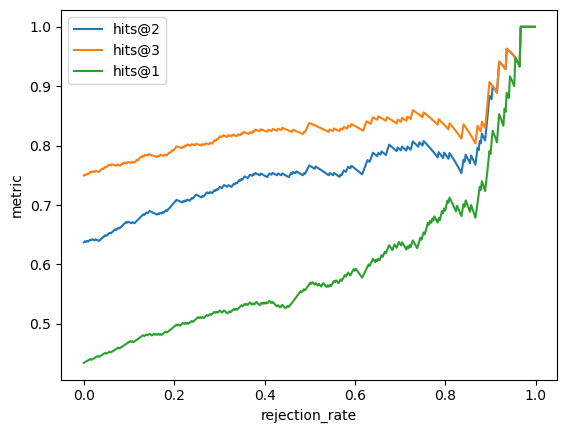

In [77]:
import matplotlib.pyplot as plt

plt.plot(curve_margin.rejection_rate, curve_margin["hits@2_accepted"],label="hits@2")
plt.plot(curve_margin.rejection_rate, curve_margin["hits@3_accepted"],label="hits@3")
plt.plot(curve_margin.rejection_rate, curve_margin["hits@1_accepted"],label="hits@1")
plt.ylabel("metric")
plt.xlabel("rejection_rate")
plt.legend()


In [57]:
best_top1, curve_top1 = find_threshold_on_validation(
    df_val=df_val,
    target_metric=0.80,
    metric_col="hit@1",
    score_col="top1_prob",
    min_coverage=0.0,
    num_thresholds=501,
)

print(best_top1)

{'threshold': 0.922, 'score_col': 'top1_prob', 'metric_col': 'hit@1', 'metric_value': 0.8055555555555556, 'coverage': 0.0851063829787234, 'n_accepted': 36, 'n_total': 423}


In [58]:
best_margin, curve_margin = find_threshold_on_validation(
    df_val=df_val,
    target_metric=0.80,
    metric_col="hit@1",
    score_col="margin",
    min_coverage=0.0,
    num_thresholds=501,
)

print(best_margin)

{'threshold': 0.87, 'score_col': 'margin', 'metric_col': 'hit@1', 'metric_value': 0.8, 'coverage': 0.08274231678486997, 'n_accepted': 35, 'n_total': 423}


In [59]:
df_test, info_test = collect_selective_predictions(
    model=model,
    data_list=test_data,
    idx_to_metalsalt=IDX_TO_METALSALT,
    target_attr="metal_salt",
    ks=ks,
    device=device,
    skip_incompatible=True,
)

print(info_test)

{'n_total': 440, 'n_eval': 419, 'n_skipped_incompatible': 21, 'n_errors': 0}


In [60]:
test_base_scores = {
    f"hits@{k}": float(df_test[f"hit@{k}"].mean())
    for k in ks
}

print("Test without rejection:")
print(test_base_scores)

Test without rejection:
{'hits@1': 0.4343675417661098, 'hits@2': 0.6372315035799523, 'hits@3': 0.7494033412887828, 'hits@5': 0.8687350835322196}


In [61]:
threshold = best_top1["threshold"]

test_reject_scores = evaluate_with_rejection(
    df=df_test,
    threshold=threshold,
    score_col="top1_prob",
    ks=ks,
)

print("Test with rejection:")
print(test_reject_scores)

Test with rejection:
{'threshold': 0.922, 'score_col': 'top1_prob', 'n_total': 419, 'n_accepted': 34, 'n_rejected': 385, 'coverage': 0.081145584725537, 'rejection_rate': 0.918854415274463, 'hits@1_accepted': 0.8529411764705882, 'hits@2_accepted': 0.9411764705882353, 'hits@3_accepted': 0.9411764705882353, 'hits@5_accepted': 1.0}


In [48]:
from fairmofsyncondition.read_write import coords_library
import numpy as np
from mofstructure import mofdeconstructor

data = data_list_loaded[10]
ase = coords_library.pytorch_geometric_to_ase(data)

mask = [bool(mofdeconstructor.is_metal(i)[0]) for i in ase.get_chemical_symbols()]
metal = np.unique(np.array(ase.get_chemical_symbols())[mask], return_counts=True)[0].item()


make_right_metal = []
for k,v in IDX_TO_METALSALT.items():
    if v[:2] == metal:
        make_right_metal.append(True)
    else:
        make_right_metal.append(False)

target_field, target_dim = "metal_salt", 134

import torch
import torch
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device= "cpu"
model = MOFConditionPredictor(
    target_dim=target_dim,
    global_fields=["lattice", "atomic_one_hot", "oms"]
)
model.load_state_dict(torch.load("best_model_metal_salt/best_model_metal_salt_seed_123.pt", map_location=device))

import torch
from torch_geometric.loader import DataLoader

top_x = 3  

for batch in DataLoader([data], batch_size=1):
    break



model.eval()

with torch.no_grad():
    logits = model(batch)  # shape: [batch_size, num_classes]

    # Se stai facendo inferenza su una sola MOF
    logits = logits[0]  # shape: [num_classes]

    # make_right_metal deve essere booleano con shape [num_classes]
    make_right_metal = torch.as_tensor(
        make_right_metal,
        dtype=torch.bool,
        device=logits.device
    )

    # get indices of valid classes (where make_right_metal is True)
    valid_class_indices = torch.where(make_right_metal)[0]

    # filter
    valid_logits = logits[valid_class_indices]

    # softmax only valid salts
    valid_probs = F.softmax(valid_logits, dim=-1)

    # top-k only on compatible salts
    top_probs, top_pos = torch.topk(
        valid_probs,
        k=min(top_x, valid_probs.numel()),
        dim=-1
    )

    # convert to original indices
    top_indices = valid_class_indices[top_pos]


for rank, (idx, prob) in enumerate(zip(top_indices, top_probs), start=1):
    idx = int(idx.item())
    prob = float(prob.item())

    name = IDX_TO_METALSALT[idx]

    print(f"{rank}. idx={idx} | prob={prob:.4f} | {name}")

1. idx=78 | prob=0.8565 | MnCl2.4H2O
2. idx=133 | prob=0.1001 | Mn(OAc)2.4H2O
3. idx=7 | prob=0.0122 | Mn(ClO4)2.6H2O


In [75]:
from pathlib import Path

from fairmofsyncondition.crystal.crystal2data import DataStructure
from fairmofsyncondition.read_write import coords_library



cif_path = Path("../../../../Zn2C43N6H29O8.cif")
#cif_path = Path("../../../../EDUSIF.cif")
#cif_path = Path("ADIQAG_fair.cif")
#cif_path = Path("REWRAN_fair.cif")
cif_path = Path("REWQUG_fair.cif")


data = DataStructure(str(cif_path)).complete_torch_data()
ase = coords_library.pytorch_geometric_to_ase(data)

In [87]:
import numpy as np
from mofstructure import mofdeconstructor

mask = [bool(mofdeconstructor.is_metal(i)[0]) for i in ase.get_chemical_symbols()]

np.unique(np.array(ase.get_chemical_symbols())[mask], return_counts=True)

(array(['Zr'], dtype='<U2'), array([8]))

(array(['C', 'H', 'N', 'O', 'Zr'], dtype='<U2'),
 array([112, 276,  12,  32,   8]))

In [69]:
target_field, target_dim = "metal_salt", 134

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device= "cpu"
model = MOFConditionPredictor(
    target_dim=target_dim,
    global_fields=["lattice", "atomic_one_hot", "oms"]
)
model.load_state_dict(torch.load("best_model_metal_salt/best_model_metal_salt_seed_123.pt", map_location=device))

import torch
from torch_geometric.loader import DataLoader

top_x = 10   

for batch in DataLoader([data], batch_size=1):
    break

model.eval()

with torch.no_grad():
    logits = model(batch)

    probs = torch.softmax(logits, dim=-1)

    top_probs, top_indices = torch.topk(
        probs,
        k=top_x,
        dim=-1
    )

for rank, (idx, prob) in enumerate(zip(top_indices[0], top_probs[0]), start=1):
    idx = int(idx.item())
    prob = float(prob.item())

    name = IDX_TO_METALSALT[idx]

    print(f"{rank}. idx={idx} | prob={prob:.4f} | {name}")

1. idx=104 | prob=0.7166 | Zn(NO3)2.6H2O
2. idx=23 | prob=0.1282 | Zn(OAc)2.2H2O
3. idx=108 | prob=0.0809 | ZnCl2
4. idx=96 | prob=0.0159 | Zn(NO3)2
5. idx=97 | prob=0.0144 | ZnI2
6. idx=119 | prob=0.0088 | Zn(OAc)2
7. idx=12 | prob=0.0081 | ZnSO4.7H2O
8. idx=54 | prob=0.0080 | Zn(NO3)2.4H2O
9. idx=126 | prob=0.0045 | Zn(ClO4)2.6H2O
10. idx=47 | prob=0.0040 | LiOH.H2O


In [11]:
from fairmofsyncondition.read_write import filetyper


t = filetyper.category_names()
t["solvents"]

['KBPLFHHGFOOTCA-UHFFFAOYSA-N',
 'WEVYAHXRMPXWCK-UHFFFAOYSA-N',
 'KXKVLQRXCPHEJC-UHFFFAOYSA-N',
 'UHOVQNZJYSORNB-UHFFFAOYSA-N',
 'VLKZOEOYAKHREP-UHFFFAOYSA-N',
 'RTZKZFJDLAIYFH-UHFFFAOYSA-N',
 'ZWEHNKRNPOVVGH-UHFFFAOYSA-N',
 'OIFBSDVPJOWBCH-UHFFFAOYSA-N',
 'MFIGJRRHGZYPDD-UHFFFAOYSA-N',
 'POILWHVDKZOXJZ-ARJAWSKDSA-M',
 'BTANRVKWQNVYAZ-UHFFFAOYSA-N',
 'BDERNNFJNOPAEC-UHFFFAOYSA-N',
 'AMQJEAYHLZJPGS-UHFFFAOYSA-N',
 'FAGUFWYHJQFNRV-UHFFFAOYSA-N',
 'IVSZLXZYQVIEFR-UHFFFAOYSA-N',
 'JWUJQDFVADABEY-UHFFFAOYSA-N',
 'SJYNFBVQFBRSIB-UHFFFAOYSA-N',
 'VZGDMQKNWNREIO-UHFFFAOYSA-N',
 'XTHFKEDIFFGKHM-UHFFFAOYSA-N',
 'LYCAIKOWRPUZTN-UHFFFAOYSA-N',
 'XDTMQSROBMDMFD-UHFFFAOYSA-N',
 'SUAKHGWARZSWIH-UHFFFAOYSA-N',
 'XEKOWRVHYACXOJ-UHFFFAOYSA-N',
 'IEJIGPNLZYLLBP-UHFFFAOYSA-N',
 'KFZMGEQAYNKOFK-UHFFFAOYSA-N',
 'PEDCQBHIVMGVHV-UHFFFAOYSA-N',
 'URLKBWYHVLBVBO-UHFFFAOYSA-N',
 'BDAGIHXWWSANSR-UHFFFAOYSA-N',
 'KMTRUDSVKNLOMY-UHFFFAOYSA-N',
 'YFNKIDBQEZZDLK-UHFFFAOYSA-N',
 'WMJMABVHDMRMJA-UHFFFAOYSA-M',
 'XLYOFN

In [41]:

data = DataStructure(str(cif_path)).complete_torch_data()



In [42]:
from fairmofsyncondition.read_write import coords_library

mof = coords_library.pytorch_geometric_to_ase(data)

[np.True_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.True_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.False_,
 np.Fa

In [56]:
set(mof.get_chemical_symbols())

{'C', 'H', 'N', 'O', 'Zr'}

In [57]:
mof.get_chemical_formula()

'C112H276N12O32Zr8'